In [1]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
# sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from impute import impute_slice_fgw_barycenter, align_by_pca
from metrics import cluster_compute_ari_and_plot

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import minimize_scalar


%load_ext autoreload
%autoreload 2

# We provide a simulated dataset. These data were curated from CARD run on PDAC data

In [2]:
import pickle
outdir = '../Data/Simulation'

with open(f'{outdir}/rest.pkl', 'rb') as f:
    r = pickle.load(f)

adata_list     = [ad.read_h5ad(f'{outdir}/slice_{t}.h5ad') for t in range(r['n_time'])]
ref_adata_out = ad.read_h5ad(f'{outdir}/ref.h5ad')

V_true_temporal         = r['V_true_temporal']
cluster_labels_temporal = r['cluster_labels_temporal']
pd_B                = r['pd_B_out']
warp_params             = r['warp_params']
region_map              = r['region_map']
params                  = r['params']


# Alternatively, we can simulate a time course with cancer invasion and sinusoidal warping

In [3]:
# V_card = pd.read_csv(outdir+'/CARD_Res_V.csv', index_col=0)

# (adata_list, V_true_temporal, cluster_labels_temporal,
#             ref_out, pd_B, warp_params, region_map) = create_realistic_data(
#     ref_adata=ref_adata_out, pd_B=pd_B, V_card=V_card,
#             region_annotation=outdir+'/clusters.csv', n_time=5,
#             invasion_prob=0.5, extra_rotate_deg=20, warp_amplitude=0.04,
#             negbinom_r=5., dom_frac=0.5, sec_frac=0.2, noise_frac=0.3, dropout_frac=0.15, seed=666
# )

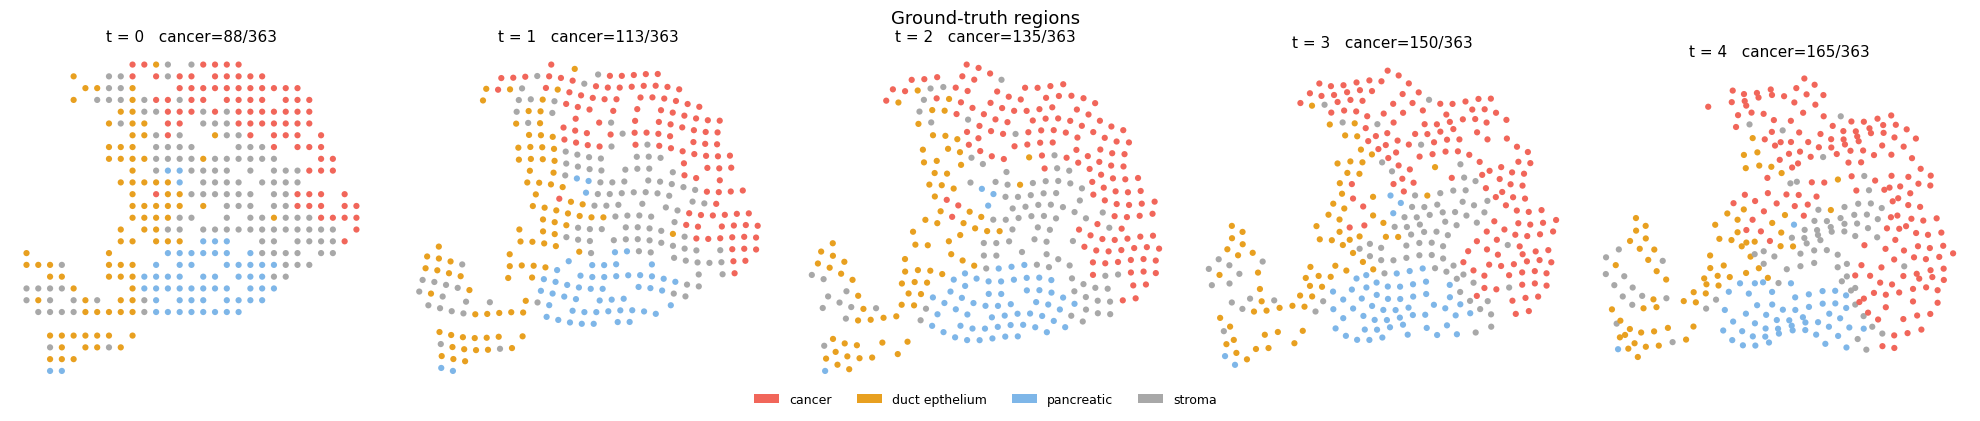

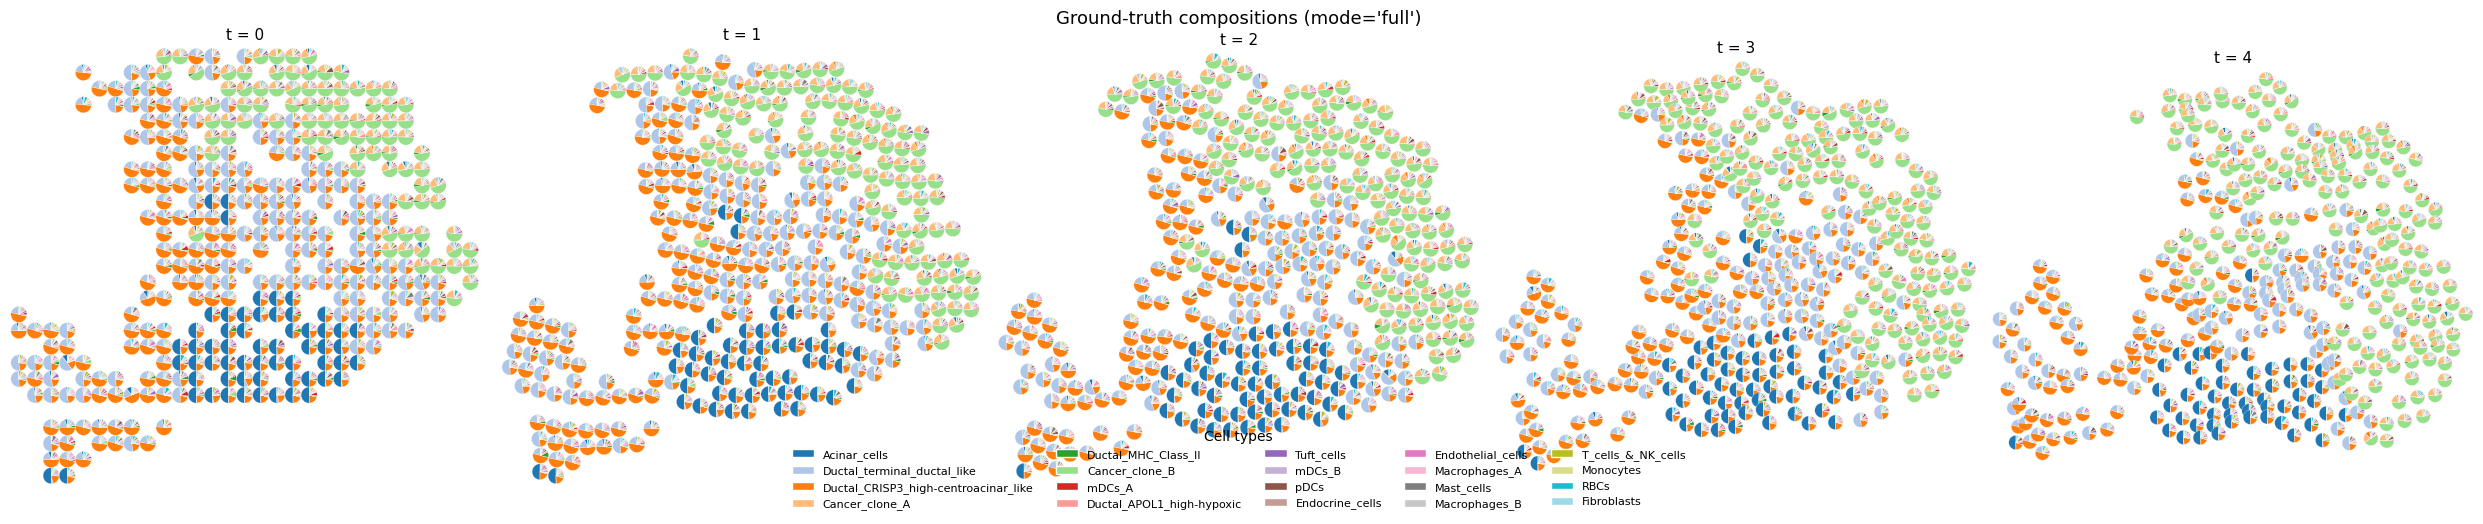

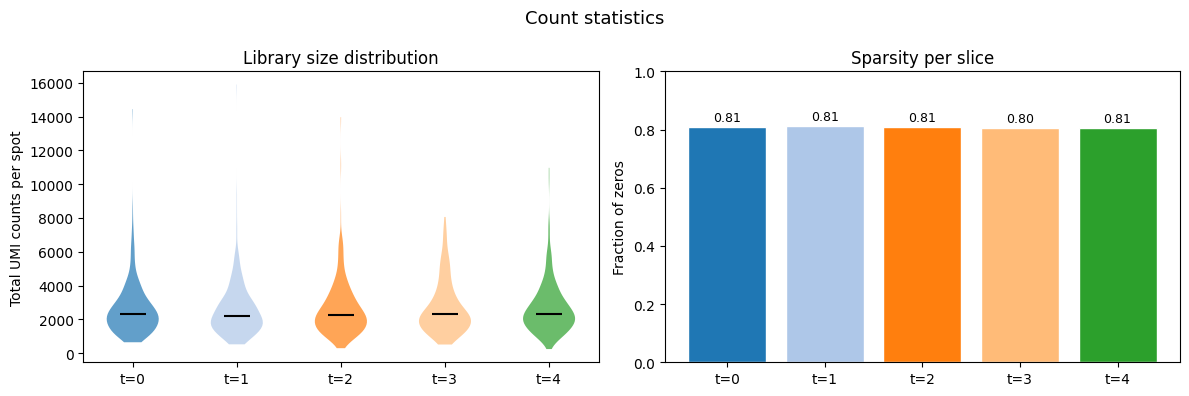

In [4]:
figs = visualize_all(
    adata_list      = adata_list,
    V_true_temporal = V_true_temporal,
    pd_B            = pd_B,
    radius          = 0.5,   
    mode            = "full",
    view="both"
)
plt.show()

# Run ATLIS

In [5]:

V_est, pi, _ = solve_V_all_slices(
        adata_list,
        pd_B,
        lam=1e3,
        mu=1e2,
        k=10,
        step_rate="automatic",
        one_step=True,
    )


iter    0  f=2.809574e+06  rel_drop=9.390e-01  mean step=2.48e-05
iter   50  f=1.879992e+06  rel_drop=1.148e-04  mean step=1.55e-05
iter  100  f=1.875980e+06  rel_drop=1.383e-05  mean step=1.53e-05
iter  111  f=1.875743e+06  rel_drop=9.867e-06  mean step=1.53e-05
stopped after iteration # 111
iter    0  f=2.642309e+06  rel_drop=9.427e-01  mean step=2.48e-05
iter   50  f=1.779300e+06  rel_drop=9.987e-05  mean step=1.58e-05
iter  100  f=1.776092e+06  rel_drop=1.221e-05  mean step=1.56e-05
iter  107  f=1.775957e+06  rel_drop=9.895e-06  mean step=1.56e-05
stopped after iteration # 107
iter    0  f=2.753907e+06  rel_drop=9.403e-01  mean step=2.48e-05
iter   50  f=1.847608e+06  rel_drop=7.487e-05  mean step=1.58e-05
iter   99  f=1.845049e+06  rel_drop=9.767e-06  mean step=1.56e-05
stopped after iteration # 99
iter    0  f=2.885098e+06  rel_drop=9.370e-01  mean step=2.48e-05
iter   50  f=1.901104e+06  rel_drop=8.653e-05  mean step=1.57e-05
iter  100  f=1.898187e+06  rel_drop=9.936e-06  mean s

# Cluster and assign labels based on ATLIS scores

In [6]:

ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
    np.vstack(V_est),
    ad.concat(adata_list),
    celltype_key="cluster",
    embedding_key="spatial",
    clustering="leiden",
    n_clusters=4,
    n_neighbors=15,
    resolution=1.0,                
    auto_resolution=True,          
    resolution_grid=None,
    random_state=0,
    plot=False
)
n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_list])
for i, adt in enumerate(adata_list):
    adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))

clustering at resolution=0.01 has been done! Found 2 clusters.
clustering at resolution=1.2 has been done! Found 13 clusters.
clustering at resolution=0.605 has been done! Found 10 clusters.
clustering at resolution=0.3075 has been done! Found 6 clusters.
clustering at resolution=0.15875 has been done! Found 4 clusters.
Leiden: target_k=4, best_resolution=0.159, n_clusters=4
ari=0.9307670066947875
nmi=0.9057341960209896


Text(0.5, 1.0, 'ATLIS')

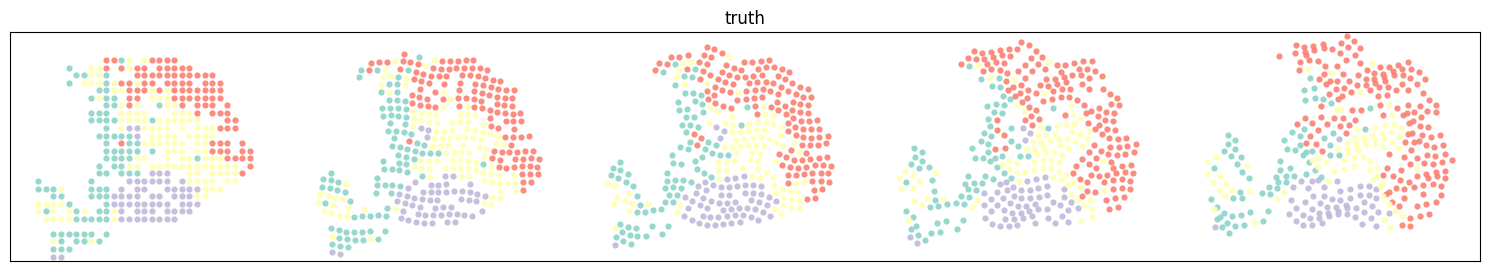

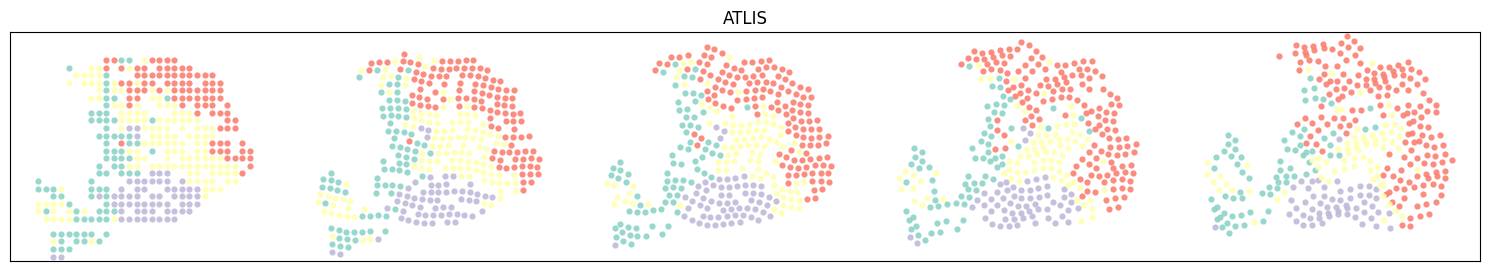

In [7]:

from matplotlib.colors import ListedColormap
colors = list(plt.get_cmap("Set3").colors)
colors = [ colors[3], colors[2], colors[0], colors[1]]

color_map = {
    0: colors[0],
    1: colors[1],
    2: colors[2],
    3: colors[3],
}

fig, ax = plot_slices_horizontal_centered(adata_list, 'cluster', x_gap=10, s=20, truth_key='cluster', legend=False, color_map=color_map)
ax.set_title('truth')

fig, ax = plot_slices_horizontal_centered(adata_list, 'pred_label', x_gap=10, s=20, truth_key='cluster', legend=False, color_map=color_map)
ax.set_title('ATLIS')


# Visualize OT coupling

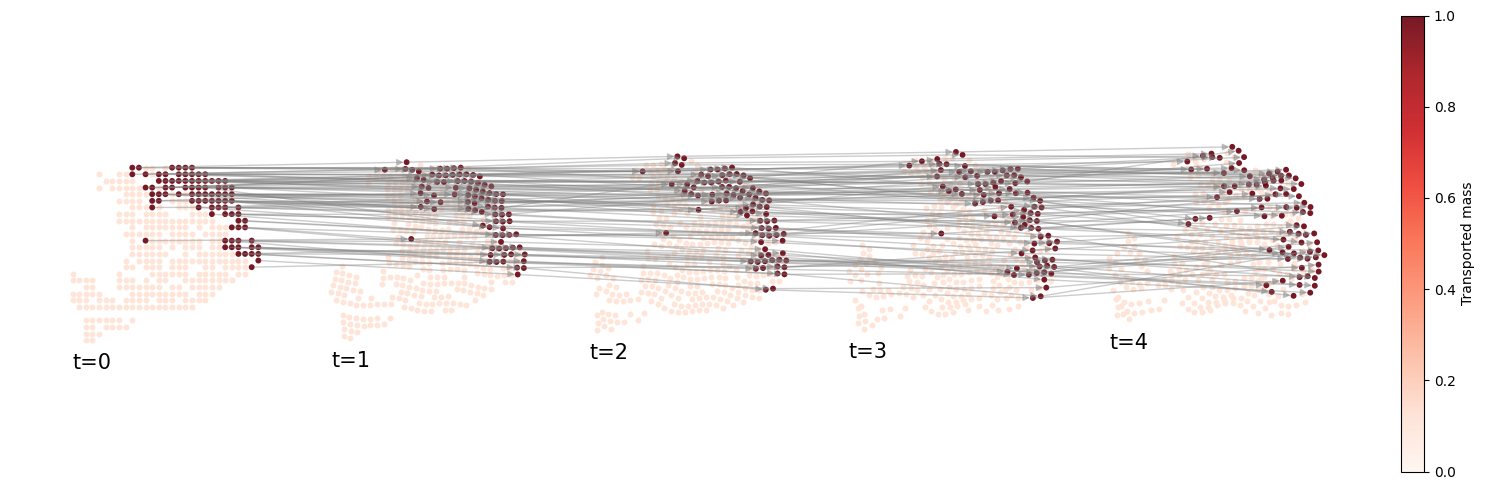

In [8]:
pi_dense = [p.toarray() if sp.issparse(p) else np.asarray(p) for p in pi]

fig, ax, _= plot_mass_transport_heatmap(
    adata_list,
    V_est,
    pi_dense,
    t_start=0,
    t_end=4, 
    source_celltype='cancer',
    celltype_obs_key="region",
    source_mass_source="obs",
    y_gap=40,
    y_scale=1,
    show_edges=True,
    n_sources_show = 100,
    alpha=0.9,
    edge_lw = 1.0,
    cmap="Reds",
    edge_alpha=0.4,
    background_color=plt.get_cmap("Reds")(0.1),
    figsize=(15,5),
    )

# Given scores at first/last slices, impute all intermediate ones

In [9]:
n_time = 5

def norm_rows(V):
    V = np.asarray(V)
    row_sum = V.sum(axis=1, keepdims=True)
    return V / np.where(row_sum == 0, 1.0, row_sum)

X1 = np.vstack([adata_list[-1].obs['x'], adata_list[-1].obs['y']]).T
X0 = np.vstack([adata_list[0].obs['x'],  adata_list[0].obs['y']]).T
Y1 = norm_rows(V_est[-1])
Y0 = norm_rows(V_est[0])

X_aligned_list = []
X_true_list    = []
Y_bar_list     = []
Y_true_list    = []


for i in range(3):
    X_bar, Y_bar, C_bar, log = impute_slice_fgw_barycenter(
        X0, Y0, X1, Y1,
        t=0.25 * (i + 1),
        N_bary=1000,
        alpha=0.5,
        random_state=42,
        
    )
    X_true        = np.vstack([adata_list[i+1].obs['x'], adata_list[i+1].obs['y']]).T
    X_bar_aligned = align_by_pca(X_bar, X_true)

    X_aligned_list.append(X_bar_aligned)
    X_true_list.append(X_true)
    Y_bar_list.append(norm_rows(Y_bar))   # normalized
    Y_true_list.append(norm_rows(V_true_temporal[i+1]))

# Pick some marker genes to visualize

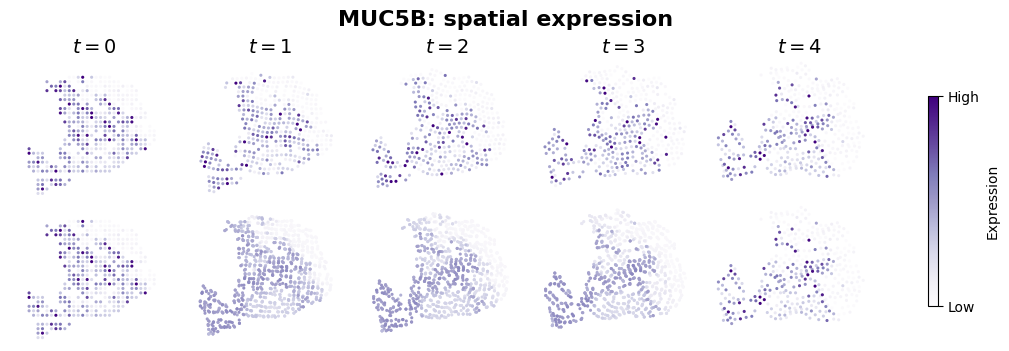

In [10]:
gene = 'MUC5B'
truth = [panel(a, gene) for a in adata_list]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="global", cmap='Purples')

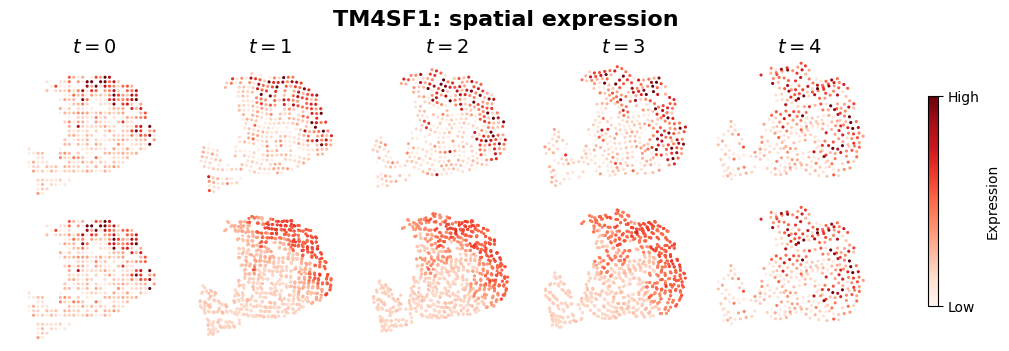

In [11]:
gene = 'TM4SF1'
truth = [panel(a, gene) for a in adata_list]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="global", cmap='Reds')